## This is some examples to use this package


In [18]:
import sys
sys.path.insert(0, "..")            # the package lives one folder up

import src                      # import Nbody before running anything in jax (CPU runtime setup)
from src import Integrator, Integrator_no_grad, State, get_default_ICs
from src.ics.initial_conditions import ElementsIC
from src.integrator.timing import calc_dtdelements
import jax
import numpy as np
import matplotlib.pyplot as plt
import logging
import time
print(jax.devices())

[CpuDevice(id=0)]


In [19]:
NAMES = list("bcdefgh")
COLORS = plt.cm.tab10(np.arange(7))

In [20]:
jax.config.update("jax_log_compiles", True)

logger = logging.getLogger("jax")
logger.setLevel(logging.WARNING)

for handler in logger.handlers[:]:
    logger.removeHandler(handler)

logger.propagate = False

handler = logging.FileHandler("jax_compile.log", mode="w")
handler.setFormatter(logging.Formatter("%(asctime)s %(message)s"))

logger.addHandler(handler)

### Compare the integrator and the jacfwd and jax.grad

In [34]:
from dataclasses import replace
tmax = 30.0
h = 0.1
ic = get_default_ICs("trappist-1")
s0 = State.from_ic(ic)
tt0 = src.create_transit_timing(tmax=tmax, ic=ic)
intr = Integrator_no_grad.default(h=h, t0=0.0, tmax=tmax)

def transit_times(m):
    """Masses (8,) -> transit times (8 bodies, ntt). Positions and velocities are kept fixed."""
    s = replace(s0, m=m)
    _, tt = intr(s, tt0)
    return tt.tt

t = time.perf_counter()
dt_dm = jax.jit(jax.jacfwd(transit_times))(s0.m)      # shape (8, ntt, 8): [planet, transit, mass of body]
jax.block_until_ready(dt_dm)
print(f"jacfwd (incl. compilation): {time.perf_counter() - t:.1f} s,  shape {dt_dm.shape}")

count = np.asarray(intr(s0, tt0)[1].count)
print("transits per planet:", count[1:])

jacfwd (incl. compilation): 23.4 s,  shape (8, 23, 8)
transits per planet: [20 13  7  4  3  2  2]


In [35]:
intr_grad = Integrator.default(h=h, t0=0.0, tmax=tmax)
t = time.perf_counter()
s_grad, tt_grad = intr_grad(State.from_ic(ic), tt0)
jax.block_until_ready((s_grad,tt_grad))

print(f"Integrator here (incl. compilation): {time.perf_counter() - t:.1f} s")
count = tt_grad.count
print("transits per planet:", count[1:])

dt_dm_pkg = np.asarray(tt_grad.dtdq0)[:, :, 6, :]        # (8, ntt, 8)

worst = 0.0
for p in range(1, 8):
    a = np.asarray(dt_dm)[p, :count[p]]
    b = dt_dm_pkg[p, :count[p]]
    worst = max(worst, np.max(np.abs(a - b)) / np.max(np.abs(b)))
print(f"max relative difference, jacfwd vs package: {worst:.1e}")

Integrator here (incl. compilation): 8.7 s
transits per planet: [20 13  7  4  3  2  2]
max relative difference, jacfwd vs package: 5.7e-13


### Runtime after compiled

In [21]:
ic = get_default_ICs("trappist-1")
s = State.from_ic(ic)
tmax = 1000.0 # max time (day) 


In [22]:
ic = get_default_ICs("trappist-1")

s = State.from_ic(ic)
tt = src.create_transit_timing(tmax=tmax,ic=ic)
Intr = Integrator_no_grad.default(h=0.1,t0=0.0,tmax=tmax,)

start = time.perf_counter()
s, tt = Intr(s, tt)
jax.block_until_ready(s)
jax.block_until_ready(tt)
print("Total time for Integrator without grad for the first time:", time.perf_counter() - start)

Total time for Integrator without grad for the first time: 4.637803355995857


In [23]:
ic = get_default_ICs("trappist-1")
Intr = Integrator_no_grad.default(h=0.1, t0=0.0, tmax=tmax)

for i in range(3):
    s = State.from_ic(ic)
    tt = src.create_transit_timing( tmax=tmax, ic=ic)
    start = time.perf_counter()
    s, tt = Intr(s, tt)
    jax.block_until_ready(s)
    jax.block_until_ready(tt)
    end = time.perf_counter()
    print(f"ReRun -Intergator without grad: {i+1}: {end-start:.4f} s")

ReRun -Intergator without grad: 1: 0.2384 s
ReRun -Intergator without grad: 2: 0.2392 s
ReRun -Intergator without grad: 3: 0.2361 s


### With grad

In [24]:
ic = get_default_ICs("trappist-1")
s = State.from_ic(ic)

In [25]:
t0 = 0.0        # Initial time
h = 0.1         # Time step
tt = src.create_transit_timing(tmax = tmax, ic = ic,)

#with grad
Intr = Integrator.default(h = h, t0 = t0, tmax = tmax)
start = time.perf_counter()
s,tt = Intr(s, tt)
jax.block_until_ready(s)
jax.block_until_ready(tt)
end = time.perf_counter()
print(f'Total time for Integrator without grad for the first time: {end - start:.4f} seconds!')

Total time for Integrator without grad for the first time: 10.3698 seconds!


In [26]:
ic = get_default_ICs("trappist-1")

Intr = Integrator.default(h=0.1, t0=0.0, tmax=tmax)

for i in range(3):
    s = State.from_ic(ic)
    tt = src.create_transit_timing( tmax=tmax, ic=ic)
    start = time.perf_counter()
    s, tt = Intr(s, tt)
    jax.block_until_ready(s)
    jax.block_until_ready(tt)
    end = time.perf_counter()
    print(f"ReRun - Integrator with grad calculated/recorded - {i+1}: {end-start:.4f} s")                     

ReRun - Integrator with grad calculated/recorded - 1: 1.6600 s
ReRun - Integrator with grad calculated/recorded - 2: 1.6729 s
ReRun - Integrator with grad calculated/recorded - 3: 1.6656 s


In [27]:
print('count:', tt.count)
print('tt:', tt.tt)
print('ntt:', tt.ntt)
print('gsave: ', tt.gsave)


count: [  0 662 413 247 163 109  81  54]
tt: [[ 0.          0.          0.         ...  0.          0.
   0.        ]
 [ 0.79053962  2.30223396  3.81326796 ...  0.          0.
   0.        ]
 [ 0.45349103  2.87488048  5.29674126 ...  0.          0.
   0.        ]
 ...
 [ 2.64920503 11.85743305 21.06523851 ...  0.          0.
   0.        ]
 [ 5.87594408 18.2273673  30.57983533 ...  0.          0.
   0.        ]
 [ 0.64619779 19.37745733 38.11249612 ...  0.          0.
   0.        ]]
ntt: 665
gsave:  [ 0.00000000e+00  6.54022648e-08 -1.89322982e-04 -7.19096213e-05
 -6.22483636e-04 -2.53470160e-03 -1.38846304e-03 -2.50025855e-03]


### Plot the tranist timing

In [28]:
TOFF = 7300.0
d = np.genfromtxt('./Examples/T1_timings_20191203.txt', delimiter= ',')
planet = d[:, 0].astype(int)
epoch  = d[:, 1].astype(int)
tobs   = d[:, 2] - TOFF
terr   = d[:, 3]
print(f"{len(d)} transits:", {NAMES[p-1]: int((planet == p).sum()) for p in range(1, 8)})
print(f"time span: {d[:,2].min():.1f} to {d[:,2].max():.1f}  (BJD − 2450000)")

447 transits: {'b': 161, 'c': 107, 'd': 53, 'e': 49, 'f': 33, 'g': 30, 'h': 14}
time span: 7282.8 to 8785.4  (BJD − 2450000)


In [29]:
base = get_default_ICs("trappist-1")
H = np.asarray(base.epsilon)                       # hierarchy matrix
el_default = np.array(base.elements)
el_default[1:, 2] -= TOFF

t0   = 7257.93115525 - TOFF - 0.5                  # start before the first transit
tmax = 8790.0 - TOFF - t0                          # integrate past the last observed transit
h    = 0.0600

print(f"Current integration time: {tmax:2f}, and the time step is {h: 4f}.")
intr = Integrator.default(h=h, t0=t0, tmax=tmax)
tt_template = src.create_transit_timing(tmax=tmax, ic=ElementsIC(t0, H, el_default))

FREE = [0, 1, 2, 3, 4]                         # fit m, P, t0, e cosω, e sinω of each planet (ElementsIC index)
JCOL = {0: 6, 1: 0, 2: 1, 3: 2, 4: 3}          # same quantities on the dtdelements element axis

def model(el):
    """Transit times (n, ntt), counts (n,) and d(times)/d(elements) (n, ntt, 7, n)."""
    ic = ElementsIC(t0, H, el)
    s, tt = intr(State.from_ic(ic), tt_template)
    tt = calc_dtdelements(s, tt)
    return np.asarray(tt.tt), np.asarray(tt.count), np.asarray(tt.dtdelements)

start = time.perf_counter()
T_def, C_def, _ = model(el_default)
print(f"first call (includes compilation): {time.perf_counter() - start:.1f} s")
start = time.perf_counter()
T_def, C_def, _ = model(el_default)
print(f"second call: {time.perf_counter() - start:.1f} s. Does it become smaller?")
print(f"transits per planet: {C_def[1:]}")

Current integration time: 1532.568845, and the time step is  0.060000.
first call (includes compilation): 3.9 s
second call: 3.9 s. Does it become smaller?
transits per planet: [1015  633  378  252  166  125   82]


In [30]:
offset = {}
for p in range(1, 8):
    sel = planet == p
    nearest = np.array([np.argmin(np.abs(T_def[p, :C_def[p]] - t)) for t in tobs[sel]])
    offset[p] = int(np.round(np.median(nearest - epoch[sel])))
k = epoch + np.array([offset[p] for p in planet])       # model transit index of each observation
print("epoch offsets:", offset)

epoch offsets: {1: 43, 2: 10, 3: 74, 4: 9, 5: 6, 6: 3, 7: 21}


### Default elements vs data 20191203

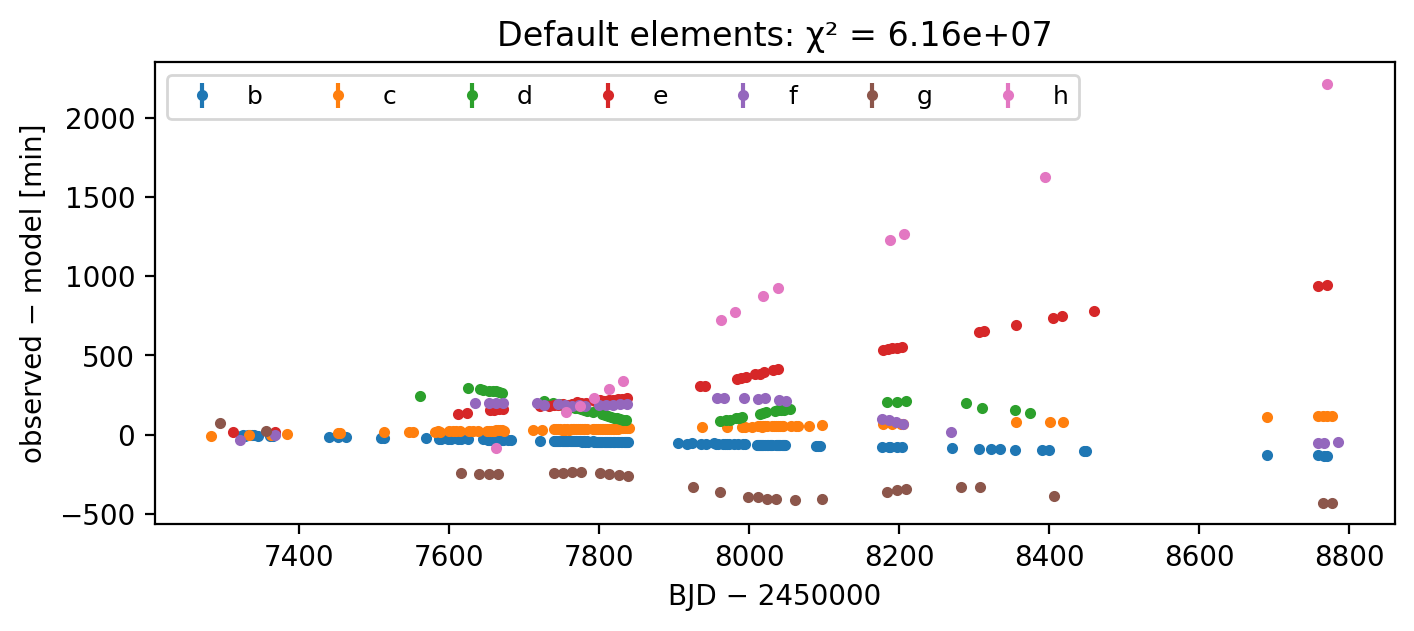

In [31]:
res_def = (tobs - T_def[planet, k]) * 1440            # minutes
fig, ax = plt.subplots(figsize=(8, 3), dpi = 200)
for p in range(1, 8):
    sel = planet == p
    ax.errorbar(tobs[sel] + TOFF, res_def[sel], terr[sel] * 1440, fmt="o", ms=3, color=COLORS[p-1], label=NAMES[p-1])
ax.set(xlabel="BJD − 2450000", ylabel="observed − model [min]",
       title=f"Default elements: χ² = {np.sum((res_def / (terr * 1440))**2):.3g}")
ax.legend(ncol=7, fontsize=9)
plt.show()

### Fit with exact gradients

In [32]:
def residuals_and_jacobian(el):
    T, C, D = model(el)
    if not np.all(k < C[planet]):                 # a transit fell outside the integration window
        return None, None
    r = (tobs - T[planet, k]) / terr
    J = np.stack([D[planet, k, JCOL[e], b] for b in range(1, 8) for e in FREE], axis=1) / terr[:, None]
    return r, J

def update(el, dp):
    el = el.copy()
    el[1:, FREE] += dp.reshape(7, len(FREE))
    return el

el = el_default.copy()
lam = 1e-3
r, J = residuals_and_jacobian(el)
chi2 = r @ r
history = [chi2]
print(f"iter 0: chi2 = {chi2:.6g}")
start = time.perf_counter()
for it in range(1, 30):
    A, g = J.T @ J, J.T @ r
    while True:
        dp = np.linalg.solve(A + lam * np.diag(np.diag(A)), g)
        el_try = update(el, dp)
        r_try, J_try = residuals_and_jacobian(el_try)
        chi2_try = np.inf if r_try is None else r_try @ r_try
        if chi2_try < chi2 or lam > 1e8:
            break
        lam *= 10
    if chi2_try >= chi2:
        break
    converged = chi2 - chi2_try < 1e-4 * chi2
    el, r, J, chi2, lam = el_try, r_try, J_try, chi2_try, lam / 10
    history.append(chi2)
    print(f"iter {it}: chi2 = {chi2:.6g}")
    if converged:
        break
print(f"fit time {time.perf_counter() - start:.1f} s;  chi2 = {chi2:.1f} for {len(r)} transits, "
      f"{J.shape[1]} parameters (chi2/dof = {chi2 / (len(r) - J.shape[1]):.2f})")

cov = np.linalg.inv(J.T @ J)                        # Fisher-matrix covariance at the best fit
sigma = np.sqrt(np.diag(cov)).reshape(7, len(FREE))
el_fit = el

iter 0: chi2 = 6.15935e+07
iter 1: chi2 = 3.30022e+06
iter 2: chi2 = 953358
iter 3: chi2 = 442994
iter 4: chi2 = 368034
iter 5: chi2 = 50322.4
iter 6: chi2 = 21732.3
iter 7: chi2 = 700.499
iter 8: chi2 = 654.82
iter 9: chi2 = 654.343
iter 10: chi2 = 654.343
fit time 46.9 s;  chi2 = 654.3 for 447 transits, 35 parameters (chi2/dof = 1.59)


### Transit-timing variations

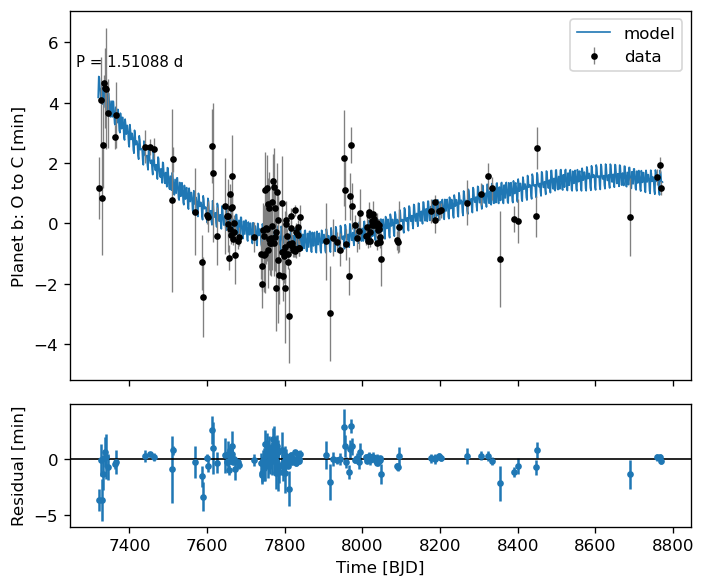

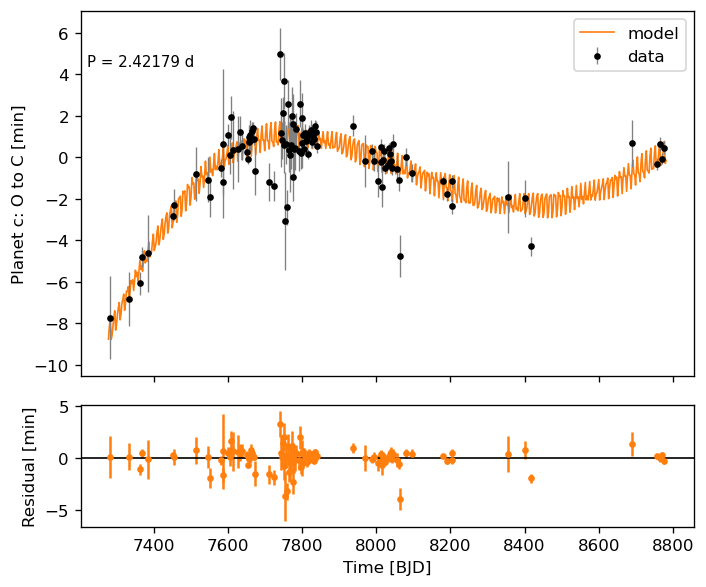

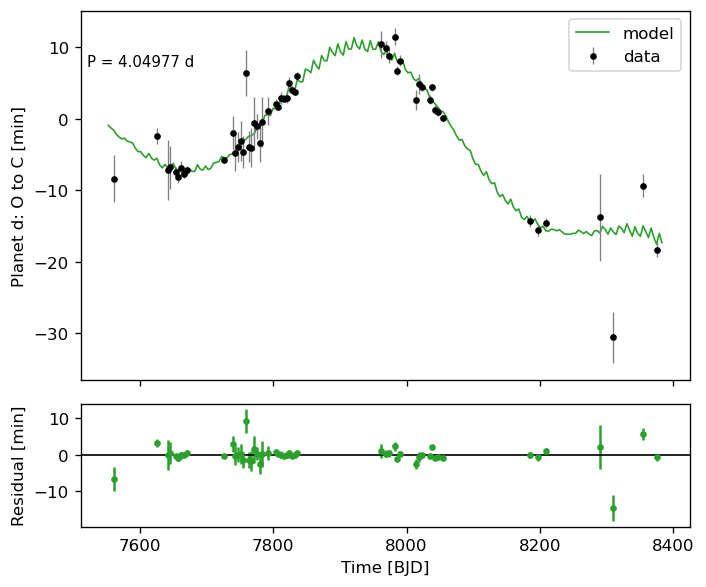

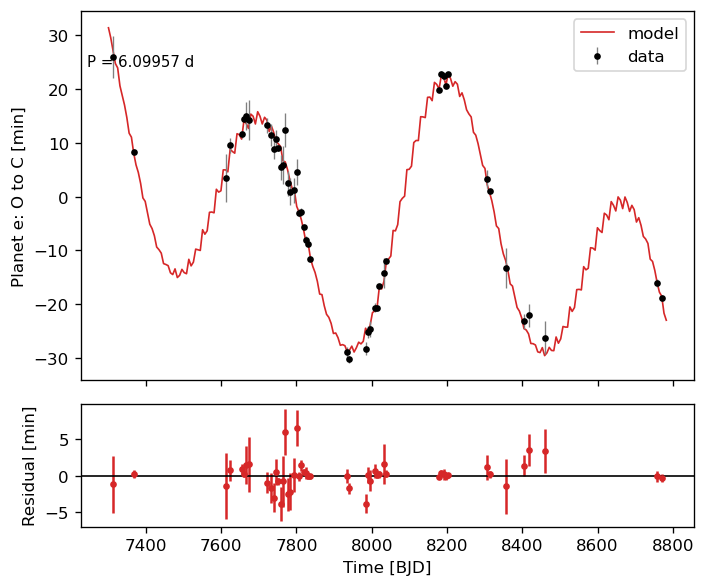

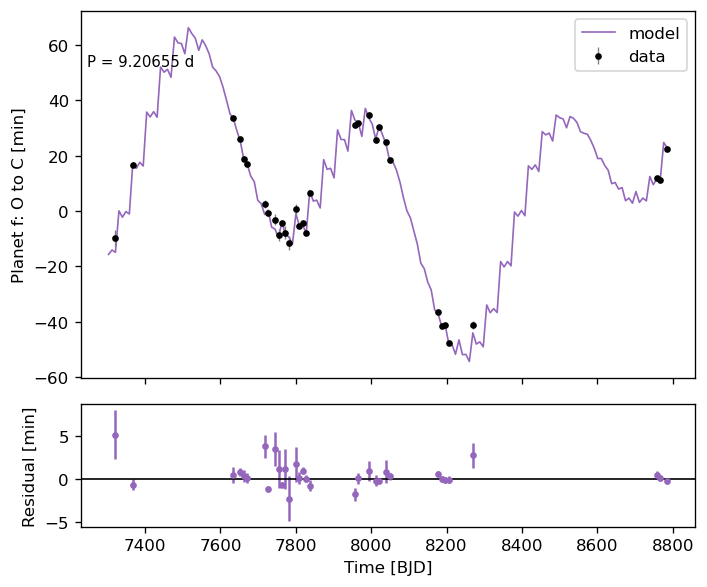

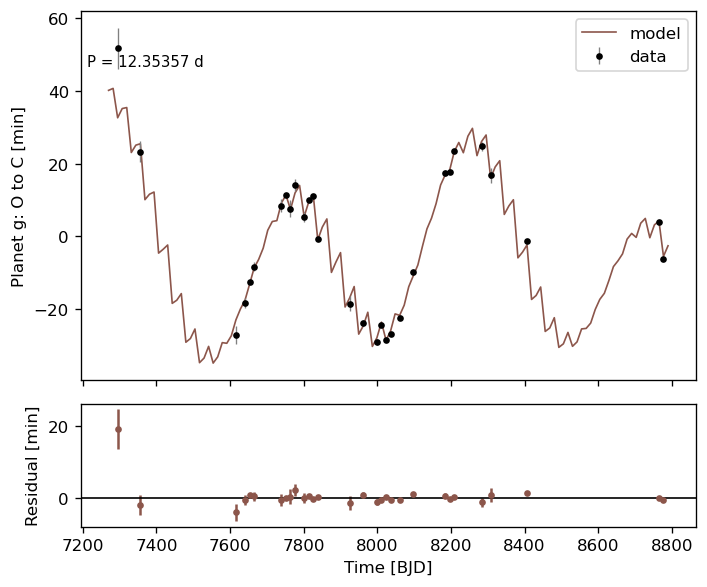

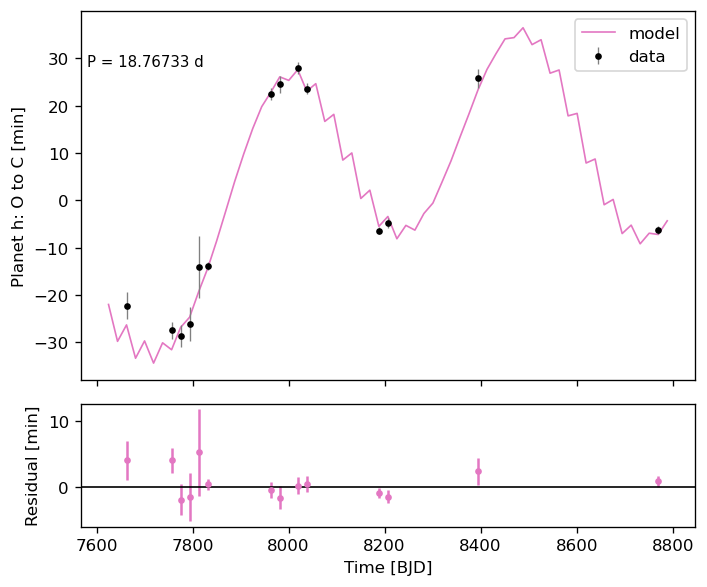

In [33]:
T_fit, C_fit, _ = model(el_fit)
res_fit = (tobs - T_fit[planet, k]) * 1440
for p in range(1, 8):
    fig, (ax1, ax2) = plt.subplots(2,1, figsize = (6, 5),dpi = 120, sharex = True, gridspec_kw= {'height_ratios': [3,1]})

    sel = planet == p
    w = 1 / terr[sel]**2
    P_lin, T0_lin = np.polyfit(k[sel], tobs[sel], 1, w=np.sqrt(w))
    n_all = np.arange(k[sel].min() - 2, k[sel].max() + 3)
    n_all = n_all[(n_all >= 0) & (n_all < C_fit[p])]

    ax1.plot(T_fit[p, n_all] + TOFF, (T_fit[p, n_all] - (T0_lin + P_lin * n_all)) * 1440, "-", color=COLORS[p-1], lw=1, label = 'model')
    ax1.errorbar(tobs[sel] + TOFF, (tobs[sel] - (T0_lin + P_lin * k[sel])) * 1440, terr[sel] * 1440,
                fmt="o", ms=3, color="k", ecolor="0.5", lw=0.8, label = 'data')
    ax1.set_ylabel(f"Planet {NAMES[p-1]}: O to C [min]")
    ax1.text(0.01, 0.85, f"P = {P_lin:.5f} d", transform=ax1.transAxes, fontsize=9)
    ax1.legend()

    ax2.errorbar(tobs[sel] + TOFF, res_fit[sel], terr[sel] * 1440, fmt="o", ms=3, color=COLORS[p-1], label=NAMES[p-1])
    ax2.axhline(0, c = 'k', lw = 1)
    ax2.set_ylabel("Residual [min]")
    ax2.set_xlabel("Time [BJD]")
    
    plt.tight_layout()
    plt.show()

### Kepler 51